<a href="https://colab.research.google.com/github/Innej3/Synchronize/blob/main/ESN_Synchronization_Logistic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
Anticipating synchronization with machine learning: https://arxiv.org/pdf/2103.13358

replication
"""

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
'''
Can the ESN predict the synchronization at eps = 0.25, having trained only on the
decynchronzied part?

How did we know that at eps = 0.25 they should synchronize ?
-> can calculate it using the Master Stability Function (msf)

'''

In [ ]:
def F(x):
  # logistc map
  return 4.0 * x * (1.0 - x)

In [ ]:
F(np.random.random(2))

array([0.24526857, 0.95766981])

In [ ]:
def coupled_logistic(eps, T, T_trans=1000, seed=0):
  rng = np.random.default_rng(seed)
  x = rng.random(2)
  out = np.zeros((T, 2))
  for n in range(T_trans+T):
    fx = F(x)
    x = fx + eps * (fx[::-1] - fx) # diffuse coupling
    if n >= T_trans:
      out[n-T_trans] = x
  return out

In [ ]:
def sync_error(u):
  return np.mean(np.abs(u[:, 0] - u[:, 1]))

In [ ]:
class PAReservoir:
  def __init__(self, D_in, D_r=100, p=0.2, sigma=1.0, rho=1e-5, alpha=1.0,
               eps_k=1.0, eps_bias=0.0, lam=1e-5, seed=0):
    rng = np.random.default_rng(seed)
    A = rng.uniform(-1, 1, (D_r, D_r)) * (rng.random((D_r, D_r)) < p)
    self.A = A * rho / np.max(np.abs(np.linalg.eigvals(A)))
    self.W_in = rng.uniform(-sigma, sigma, (D_r, D_in))
    self.b = rng.uniform(-1, 1, D_r)
    self.alpha, self.eps_k, self.eps_bias, self.lam = alpha, eps_k, eps_bias, lam
    self.D_r = D_r

  def step(self, r, u, eps):
    pre = self.A @ r + self.W_in @ u + self.eps_k * (eps + self.eps_bias) * self.b
    return (1 - self.alpha) * r + self.alpha * np.tanh(pre)

  def feat(self, r):
    f = r.copy()
    f[1::2] = f[1::2] ** 2 # why are we squarring every odd number cause tanh is odd function and
    return f # logistic is an even func thus it can only represent odd maps, thus by sqaurring half
    # the neurons adds even features so the readout can vuilt both odd and even parts

  def fit(self, series_list, eps_list, washout=100):
    Fm, U = [], []
    for u, eps in zip(series_list, eps_list):
      r = np.zeros(self.D_r)
      for t in range(len(u) - 1):
        r = self.step(r, u[t], eps)
        if t >= washout:
          Fm.append(self.feat(r))
          U.append(u[t+1])

    Fm, U = np.array(Fm), np.array(U).T
    # ORDINARY LEAST SQAURES (U'Fm)(Fm'Fm + lam*I)^-1 (ridge regression)
    self.W_out = U @ Fm @ np.linalg.inv(Fm.T @ Fm + self.lam * np.eye(self.D_r))


  def predict(self, u_warm, eps, n_steps):
    r = np.zeros(self.D_r)
    for u in u_warm:
      r = self.step(r, u, eps)
    v = self.W_out @ self.feat(r)
    out = np.zeros((n_steps, len(v)))
    for t in range(n_steps):
      out[t] = v
      r = self.step(r, v, eps)
      v = self.W_out @ self.feat(r)
    return out

In [ ]:
train_eps = [0.20, 0.22, 0.24]
train = [coupled_logistic(e, T=2000, seed=i) for i, e in enumerate(train_eps)]

In [ ]:
rc = PAReservoir(D_in=2)
rc.fit(train, train_eps)

In [ ]:
sweep = np.arange(0.18, 0.2701, 0.005)
dx_true, dx_rc = [], []
for e in sweep:
  u = coupled_logistic(e, T=1100, seed=99)
  dx_true.append(sync_error(u[100:]))
  pred = rc.predict(u[:100], e, n_steps=1000)
  dx_rc.append(sync_error(pred) if np.all(np.isfinite(pred)) else np.nan)
  print(f"eps={e:.3f}  true={dx_true[-1]:.4f}  RC={dx_rc[-1]:.4f}")

eps=0.180  true=0.3900  RC=0.3825
eps=0.185  true=0.3796  RC=0.3739
eps=0.190  true=0.3685  RC=0.3643
eps=0.195  true=0.1993  RC=0.2002
eps=0.200  true=0.1227  RC=0.1159
eps=0.205  true=0.0992  RC=0.0998
eps=0.210  true=0.1063  RC=0.0953
eps=0.215  true=0.0823  RC=0.0747
eps=0.220  true=0.0776  RC=0.0873
eps=0.225  true=0.0579  RC=0.0677
eps=0.230  true=0.0511  RC=0.0576
eps=0.235  true=0.0412  RC=0.0395
eps=0.240  true=0.0239  RC=0.0341
eps=0.245  true=0.0127  RC=0.0066
eps=0.250  true=0.0010  RC=0.0033
eps=0.255  true=0.0000  RC=0.0022
eps=0.260  true=0.0000  RC=0.0016
eps=0.265  true=0.0000  RC=0.0015
eps=0.270  true=0.0000  RC=0.0014


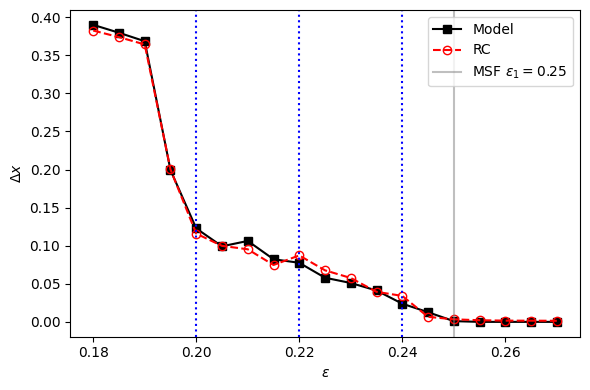

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sweep, dx_true, 'ks-', label='Model')
plt.plot(sweep, dx_rc, 'ro--', mfc='none', label='RC')
for e in train_eps:
  plt.axvline(e, ls=':', c='b')
plt.axvline(0.25, c='gray', alpha=0.5, label=r'MSF $\epsilon_1=0.25$')
plt.xlabel(r'$\epsilon$'); plt.ylabel(r'$\Delta x$'); plt.legend(); plt.tight_layout()
plt.show()

In [ ]:
'''
Every seed initalizes A, W_in and b differently and since they are fixed. Thats why
different seeds can result in different sync errors.
'''

In [ ]:
seeds = range(5)
dx_rc_all = []
for s in seeds:
  rc = PAReservoir(D_in=2, seed=s)
  rc.fit(train, train_eps)
  row = []
  for e in sweep:
    u = coupled_logistic(e, T=1100, seed=99)
    pred = rc.predict(u[:100], e, n_steps=1000)
    row.append(sync_error(pred) if np.all(np.isfinite(pred)) else np.nan)
  dx_rc_all.append(row)
dx_rc_all = np.array(dx_rc_all)

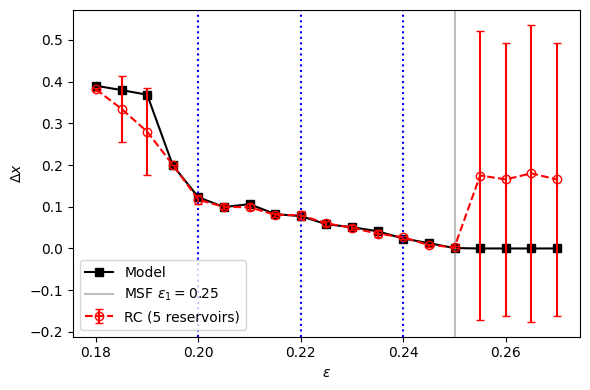

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sweep, dx_true, 'ks-', label='Model')
plt.errorbar(sweep, np.nanmean(dx_rc_all, 0), onp.nanstd(dx_rc_all, 0),
             fmt='ro--', mfc='none', capsize=3, label='RC (5 reservoirs)')
for e in train_eps:
  plt.axvline(e, ls=':', c='b')
plt.axvline(0.25, c='gray', alpha=0.5, label=r'MSF $\epsilon_1=0.25$')
plt.xlabel(r'$\epsilon$'); plt.ylabel(r'$\Delta x$'); plt.legend(); plt.tight_layout()
plt.show()

In [ ]:
'''
So why the error in prediction at 0.18 ? because the model didnt see that value at
training so it had to extrapolate which might result in the mdoel predict
a value say not in the range of [0, 1], and since the model is only used to seeing input
in the range of [0, 1]. it produced even wilder value and got trapped into a fake
outisde attractor

The machine was trained on data that rarely touches the edge. Small errors in its
learned map near x=0.5 -> 1 rarely matters during training and now they're fatal.
The further past the training range $\epsilion$ is the larger the extrapolation
error and more often an overshoot happends.

In dynamical system theory this is called boundary crisis or ghost attractor - the
machine learning model accurately learned the shape of the chaotic attractor on the
inside, but because of random weight initialization (seed), a small "leak" or hole
opened up at the boundary $[0, 1]$ when $\epsilon$ was pushed outside the training
range.

'''

In [ ]:
'''
Parameter aware reservoir prediction past the transition is realiable for only about 83% - 90%
of reservoirs, and reliability deacays with distance from the training range.
'''

In [ ]:
'''
So below we tried we different values of $\epsilon$ to check if the same extrapolation issue arises
But suprisingly when trained at $\epsilon=$  value in train_eps2 = [0.18, 0.20, 0.22],


'''

In [ ]:
n_res = 30
dx_all = np.full((n_res, len(sweep)), np.nan)
failed = np.zeros((n_res, len(sweep)), dtype=bool)

for s in range(n_res):
  rc = PAReservoir(D_in=2, seed=s)
  rc.fit(train, train_eps)
  for i, e in enumerate(sweep):
    u = coupled_logistic(e, T=1100, seed=99)
    pred = rc.predict(u[:100], e, n_steps=1000)
    ok = np.all(np.isfinite(pred)) and pred.min() > -0.05 and pred.max() < 1.05
    failed[s, i] = not ok
    dx_all[s, i] = sync_error(pred) if np.all(np.isfinite(pred)) else np.nan

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
for s in range(n_res):
  ax1.plot(sweep, dx_all[s], color='red', alpha=0.15, lw=1)
ax1.plot(sweep, np.nanmedian(dx_all, 0), 'ro-', mfc='none', label='RC median')
ax1.plot(sweep, dx_true, 'ks-', label='Model')
ax1.set_ylim(-0.02, 0.5)
ax1.set_ylabel(r'$\Delta x$')
ax1.legend()

ax2.plot(sweep, failed.mean(0), 'k^-')
ax2.set_ylabel('failure rate')
ax2.set_xlabel(r'$\epsilon$')

for ax in (ax1, ax2):
  for e in train_eps:
    ax.axvline(e, ls=':', c='b')
  ax.axvline(0.25, c='gray', alpha=0.5)
plt.tight_layout(); plt.show()

In [ ]:
train_eps2 = [0.18, 0.20, 0.22]

In [ ]:
train2 = [coupled_logistic(e, T=2000, seed=i) for i, e in enumerate(train_eps2)]

In [ ]:
rc2 = PAReservoir(D_in=2)
rc2.fit(train2, train_eps2)

In [ ]:
sweep = np.arange(0.18, 0.2701, 0.005)
dx_true, dx_rc = [], []
for e in sweep:
  u = coupled_logistic(e, T=1100, seed=99)
  dx_true.append(sync_error(u[100:]))
  pred = rc2.predict(u[:100], e, n_steps=1000)
  dx_rc.append(sync_error(pred) if np.all(np.isfinite(pred)) else np.nan)
  print(f"eps={e:.3f}  true={dx_true[-1]:.4f}  RC={dx_rc[-1]:.4f}")

eps=0.180  true=0.3900  RC=0.3900
eps=0.185  true=0.3796  RC=0.3808
eps=0.190  true=0.3685  RC=0.3707
eps=0.195  true=0.1993  RC=0.1997
eps=0.200  true=0.1227  RC=0.1165
eps=0.205  true=0.0992  RC=0.0952
eps=0.210  true=0.1063  RC=0.1094
eps=0.215  true=0.0823  RC=0.0849
eps=0.220  true=0.0776  RC=0.0628
eps=0.225  true=0.0579  RC=0.0476
eps=0.230  true=0.0511  RC=0.0405
eps=0.235  true=0.0412  RC=0.0363
eps=0.240  true=0.0239  RC=0.0189
eps=0.245  true=0.0127  RC=0.0080
eps=0.250  true=0.0010  RC=0.0032
eps=0.255  true=0.0000  RC=0.0022
eps=0.260  true=0.0000  RC=0.0022
eps=0.265  true=0.0000  RC=0.0020
eps=0.270  true=0.0000  RC=0.0021


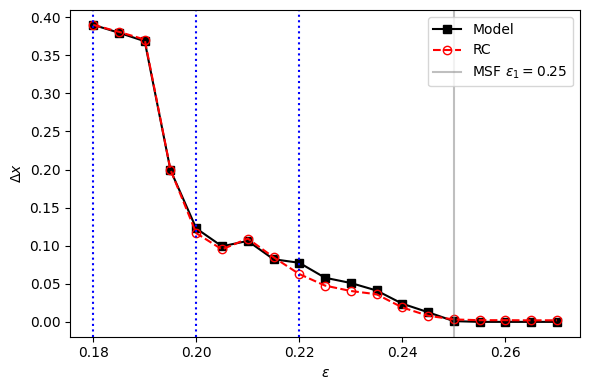

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sweep, dx_true, 'ks-', label='Model')
plt.plot(sweep, dx_rc, 'ro--', mfc='none', label='RC')
for e in train_eps2:
  plt.axvline(e, ls=':', c='b')
plt.axvline(0.25, c='gray', alpha=0.5, label=r'MSF $\epsilon_1=0.25$')
plt.xlabel(r'$\epsilon$'); plt.ylabel(r'$\Delta x$'); plt.legend(); plt.tight_layout()
plt.show()

In [ ]:
seeds = range(5)
dx_rc_all = []
for s in seeds:
  rc2 = PAReservoir(D_in=2, seed=s)
  rc2.fit(train2, train_eps2)
  row = []
  for e in sweep:
    u = coupled_logistic(e, T=1100, seed=99)
    pred = rc2.predict(u[:100], e, n_steps=1000)
    row.append(sync_error(pred) if np.all(np.isfinite(pred)) else np.nan)
  dx_rc_all.append(row)
dx_rc_all = np.array(dx_rc_all)

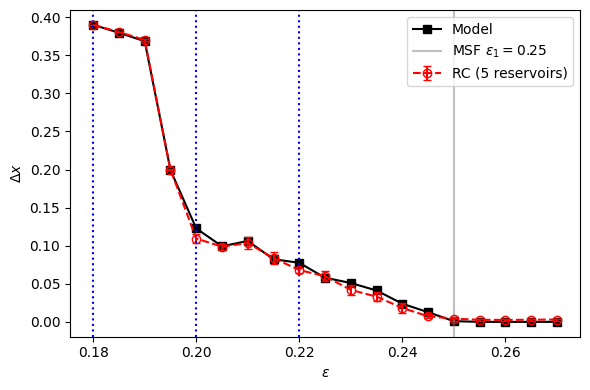

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sweep, dx_true, 'ks-', label='Model')
plt.errorbar(sweep, np.nanmean(dx_rc_all, 0), np.nanstd(dx_rc_all, 0),
             fmt='ro--', mfc='none', capsize=3, label='RC (5 reservoirs)')
for e in train_eps2:
  plt.axvline(e, ls=':', c='b')
plt.axvline(0.25, c='gray', alpha=0.5, label=r'MSF $\epsilon_1=0.25$')
plt.xlabel(r'$\epsilon$'); plt.ylabel(r'$\Delta x$'); plt.legend(); plt.tight_layout()
plt.show()

In [ ]:
train_eps3 = [0.21, 0.23, 0.245]
train3 = [coupled_logistic(e, T=2000, seed=i) for i, e in enumerate(train_eps3)]

In [ ]:
rc3 = PAReservoir(D_in=2)
rc3.fit(train3, train_eps3)

In [ ]:
sweep = np.arange(0.18, 0.2701, 0.005)
dx_true, dx_rc = [], []
for e in sweep:
  u = coupled_logistic(e, T=1100, seed=99)
  dx_true.append(sync_error(u[100:]))
  pred = rc3.predict(u[:100], e, n_steps=1000)
  dx_rc.append(sync_error(pred) if np.all(np.isfinite(pred)) else np.nan)
  print(f"eps={e:.3f}  true={dx_true[-1]:.4f}  RC={dx_rc[-1]:.4f}")

eps=0.180  true=0.3900  RC=0.3740
eps=0.185  true=0.3796  RC=0.3656
eps=0.190  true=0.3685  RC=0.1517
eps=0.195  true=0.1993  RC=0.1997
eps=0.200  true=0.1227  RC=0.1083
eps=0.205  true=0.0992  RC=0.1057
eps=0.210  true=0.1063  RC=0.1078
eps=0.215  true=0.0823  RC=0.0851
eps=0.220  true=0.0776  RC=0.0699
eps=0.225  true=0.0579  RC=0.0579
eps=0.230  true=0.0511  RC=0.0532
eps=0.235  true=0.0412  RC=0.0408
eps=0.240  true=0.0239  RC=0.0221
eps=0.245  true=0.0127  RC=0.0057
eps=0.250  true=0.0010  RC=0.0015
eps=0.255  true=0.0000  RC=0.0007
eps=0.260  true=0.0000  RC=0.0007
eps=0.265  true=0.0000  RC=0.0006
eps=0.270  true=0.0000  RC=0.0006


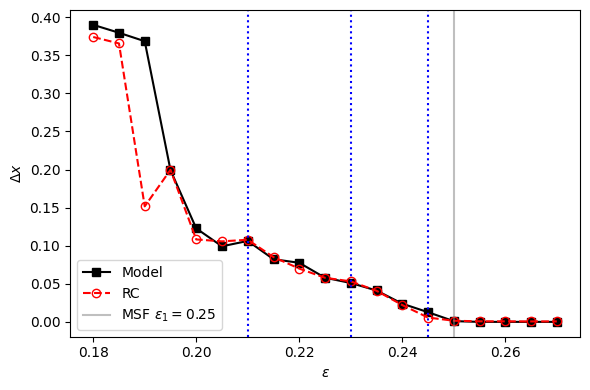

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sweep, dx_true, 'ks-', label='Model')
plt.plot(sweep, dx_rc, 'ro--', mfc='none', label='RC')
for e in train_eps3:
  plt.axvline(e, ls=':', c='b')
plt.axvline(0.25, c='gray', alpha=0.5, label=r'MSF $\epsilon_1=0.25$')
plt.xlabel(r'$\epsilon$'); plt.ylabel(r'$\Delta x$'); plt.legend(); plt.tight_layout()
plt.show()

In [ ]:
seeds = range(5)
dx_rc_all = []
for s in seeds:
  rc3 = PAReservoir(D_in=2, seed=s)
  rc3.fit(train3, train_eps3)
  row = []
  for e in sweep:
    u = coupled_logistic(e, T=1100, seed=99)
    pred = rc3.predict(u[:100], e, n_steps=1000)
    row.append(sync_error(pred) if np.all(np.isfinite(pred)) else np.nan)
  dx_rc_all.append(row)
dx_rc_all = np.array(dx_rc_all)

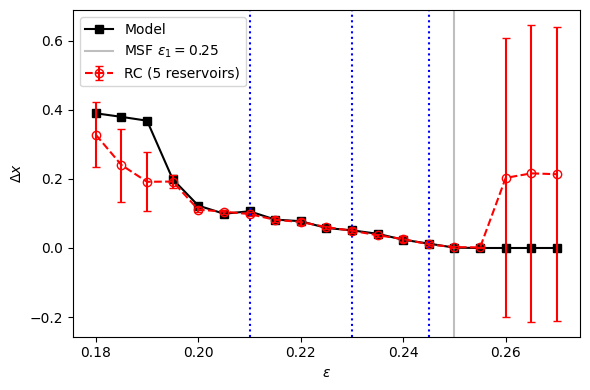

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(sweep, dx_true, 'ks-', label='Model')
plt.errorbar(sweep, np.nanmean(dx_rc_all, 0), np.nanstd(dx_rc_all, 0),
             fmt='ro--', mfc='none', capsize=3, label='RC (5 reservoirs)')
for e in train_eps3:
  plt.axvline(e, ls=':', c='b')
plt.axvline(0.25, c='gray', alpha=0.5, label=r'MSF $\epsilon_1=0.25$')
plt.xlabel(r'$\epsilon$'); plt.ylabel(r'$\Delta x$'); plt.legend(); plt.tight_layout()
plt.show()

In [ ]:
'''
Since the prediction sometimes is off, so what we can do is then clip it so the values
stay in the desired range.
  def predict_guarded(self, u_warm, eps, n_steps, lo, hi):
    r = np.zeros(self.D_r)
    for u in u_warm:
      r = self.step(r, u, eps)
    v = np.clip(self.W_out @ self.feat(r), lo, hi)
    out = np.zeros((n_steps, len(v)))
    for t in range(n_steps):
      out[t] = v
      r = self.step(r, v, eps)
      v = np.clip(self.W_out @ self.feat(r), lo, hi)
    return out

this is the updated function that we can use to preevnt that from happening.

Howver clipping will not work in everycase, like in case of rossler attractor
The only reason clipping work in case of logistic as its whole world is just a box.
[0, 1]
But incase of rossler the attractor isnt a box.
'''

In [ ]:
e = 0.27
u = coupled_logistic(e, T=1100, seed=99)
for s in range(50):
    rc = PAReservoir(D_in=2, seed=s)
    rc.fit(train, train_eps)
    p = rc.predict(u[:100], e, 1000)
    out = (p.min(1) < -0.05) | (p.max(1) > 1.05)
    if out.any():
        k = np.argmax(out)
        print(f"seed {s}: escapes at step {k}")
        print(np.round(p[k-4:k+2], 4))
        print("max |x1-x2| before escape:", np.abs(p[:k, 0] - p[:k, 1]).max().round(4))

seed 3: escapes at step 109
[[ 1.0003e+00  1.0001e+00]
 [-1.6000e-03 -4.0000e-04]
 [-5.5000e-03 -3.3000e-03]
 [-2.0100e-02 -1.6000e-02]
 [-7.7800e-02 -6.9500e-02]
 [-3.2320e-01 -3.0500e-01]]
max |x1-x2| before escape: 0.0118
seed 7: escapes at step 57
[[ 1.0006e+00  9.9990e-01]
 [-1.6000e-03  6.0000e-04]
 [-5.0000e-03 -6.0000e-04]
 [-1.6500e-02 -7.8000e-03]
 [-5.8900e-02 -4.1500e-02]
 [-2.3110e-01 -1.9390e-01]]
max |x1-x2| before escape: 0.0087
seed 9: escapes at step 41
[[ 0.0031 -0.003 ]
 [ 0.0057 -0.0058]
 [ 0.0103 -0.0115]
 [ 0.0174 -0.0239]
 [ 0.0243 -0.0543]
 [ 0.0095 -0.1436]]
max |x1-x2| before escape: 0.0413
seed 14: escapes at step 525
[[ 0.0007 -0.001 ]
 [ 0.0008 -0.0023]
 [-0.0004 -0.0059]
 [-0.0078 -0.018 ]
 [-0.0425 -0.0618]
 [-0.1982 -0.2382]]
max |x1-x2| before escape: 0.0168
seed 19: escapes at step 144
[[-0.0021  0.002 ]
 [-0.0044  0.0033]
 [-0.0101  0.0046]
 [-0.0257  0.0022]
 [-0.0759 -0.0215]
 [-0.2647 -0.1504]]
max |x1-x2| before escape: 0.0562
